# Amplitude spectral exploration

How is an activity's signal distributed over frequency, and could that help the model? The same short-time Fourier transform (STFT) is applied to three signals from `02_preprocess`:

1. **Squared difference**, $(\tilde A_t-\tilde A_{t-1})^2$: the model's signal before `log1p`.
2. **Signed difference**, $\tilde A_t-\tilde A_{t-1}$: the same change before squaring.
3. **Hampel-filtered amplitude**, $\tilde A_t$: the signal both are computed from.

The frequency axes do not all mean the same. In the filtered amplitude and the signed difference, a frequency is how fast the amplitude itself fluctuates. Squaring turns a fluctuation at $f$ into a constant plus a component at $2f$, and above 30 Hz that component folds back to $120-2f$. The squared-difference spectrogram therefore shows how fast the *motion energy* varies, not how fast the amplitude does; [below](#Why-the-squared-difference-is-flat) it turns out to be nearly flat.

This is an offline exploration of two participant sessions. Collection cues are not measured movement onsets, and every fall was recorded after every non-fall with the mattress in the room ([generalization report](../../docs/reports/generalization-2026-11-22.md)).

## Settings

Run `02_preprocess.ipynb` first; this notebook reads its staged 120 Hz arrays and writes nothing.

In [12]:
import json
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import fft as scipy_fft
from scipy.stats import rankdata

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/fall_detection").is_dir()
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fall_detection.analysis.sequence.alignment import RECEIVERS
from fall_detection.analysis.sequence.bursts import main_burst, motion_envelope
from fall_detection.analysis.sequence.cache import read_segment

SAMPLE_RATE = 120
DATASETS = ("khaelano", "akmal")
EXPORT = PROJECT_ROOT / "data/processed/amplitude_sequence" / f"{SAMPLE_RATE}hz"

# The activity shown in detail. EXAMPLE_SEGMENT picks one attempt by segment ID;
# None takes the first attempt of the activity.
EXAMPLE_DATASET = "akmal"
EXAMPLE_ACTIVITY = "walk_to_fall"
EXAMPLE_SEGMENT = None

# STFT: 64 samples = 0.53 s, so frequencies closer than about 4 Hz (half the Hann
# main lobe) are not resolved. Zero-padding to 128 only smooths the display. The
# hop is 0.067 s.
WINDOW_SAMPLES = 64
HOP_SAMPLES = 8
FFT_SAMPLES = 128
# Fewest valid samples a frame needs, as a share of its window.
MINIMUM_VALID = 0.6
THREADS = 6
# Bins below this frequency are hidden and not evaluated: a 0.53 s frame cannot
# hold a full slower cycle, and the detrend removes most of that power.
LOWEST_HZ = 1.875

SIGNALS = {
    "squared_difference": "Squared difference",
    "signed_difference": "Signed difference",
    "filtered_amplitude": "Hampel-filtered amplitude",
}
# Colour limits of the change in dB: for one attempt, and for an average.
LIMITS = {
    "squared_difference": (16, 10),
    "signed_difference": (10, 6),
    "filtered_amplitude": (10, 6),
}
FALLS = ("sit_to_fall", "stand_to_fall", "walk_to_fall")
TRANSITIONS = (
    "sit_to_stand",
    "stand_to_sit",
    "sit_to_walk",
    "walk_to_sit",
    "stand_to_walk",
    "walk_to_stand",
)

# One-hue ramp for magnitude; two hues with a gray midpoint for change.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100")
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#f9f9f7", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_red",
    ["#104281", "#3987e5", "#b7d3f6", "#f0efec", "#f3b6b5", "#e34948", "#8f1f1f"],
)
for colormap in (SEQUENTIAL, DIVERGING):
    colormap.set_bad("#c3c2b7")
plt.rcParams.update(
    {
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 10,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 9,
        "figure.facecolor": "white",
    }
)

# Frames and tones without any valid sample stay NaN by design.
warnings.filterwarnings(
    "ignore", r"Mean of empty slice|All-NaN (slice|axis) encountered", RuntimeWarning
)

segments = {
    name: pl.read_parquet(EXPORT / name / "segments.parquet") for name in DATASETS
}
for name in DATASETS:
    manifest = json.loads((EXPORT / name / "manifest.json").read_text())
    print(
        f"{name}: session {manifest['source']['session_id']}, "
        f"source {manifest['source']['source_fingerprint'][:12]}, "
        f"{len(segments[name])} segments"
    )
display(
    pl.concat(
        [
            segments[name].with_columns(pl.lit(name).alias("dataset"))
            for name in DATASETS
        ]
    )
    .group_by("activity_label", "dataset")
    .len()
    .pivot(on="dataset", index="activity_label", values="len")
    .sort("activity_label")
)

khaelano: session 20261104T081805521126Z, source 71b290a11f59, 232 segments
akmal: session 20261109T131546367822Z, source 1fbc1329d23a, 231 segments


activity_label,akmal,khaelano
str,u32,u32
"""sit_to_fall""",24,24
"""sit_to_stand""",32,32
"""sit_to_walk""",32,32
"""stand_to_fall""",31,32
"""stand_to_sit""",32,32
"""stand_to_walk""",8,8
"""walk_to_fall""",32,32
"""walk_to_sit""",32,32
"""walk_to_stand""",8,8


## Missing samples

Every receiver loses 12 consecutive samples (0.1 s) out of every 68, so no 0.53 s frame is complete. How the gaps are handled decides part of what a spectrogram shows:

- **Interpolation** invents samples. On noise it adds low-frequency power and removes high-frequency power.
- **Masking** (used here) leaves the gaps out. Each frame's linear trend is fitted to its valid samples, missing samples get weight zero, and the power is divided by the summed squared weights. White noise stays flat, but a strong component leaks into neighbouring frequencies.

The check below applies an actual receiver's gaps to synthetic signals whose spectrum is known.

rx-1: 18.0% missing, 23 gaps of 12 samples, 2 others
rx-2: 17.3% missing, 23 gaps of 12 samples, 0 others
rx-3: 17.7% missing, 22 gaps of 12 samples, 3 others
rx-4: 19.2% missing, 24 gaps of 12 samples, 2 others


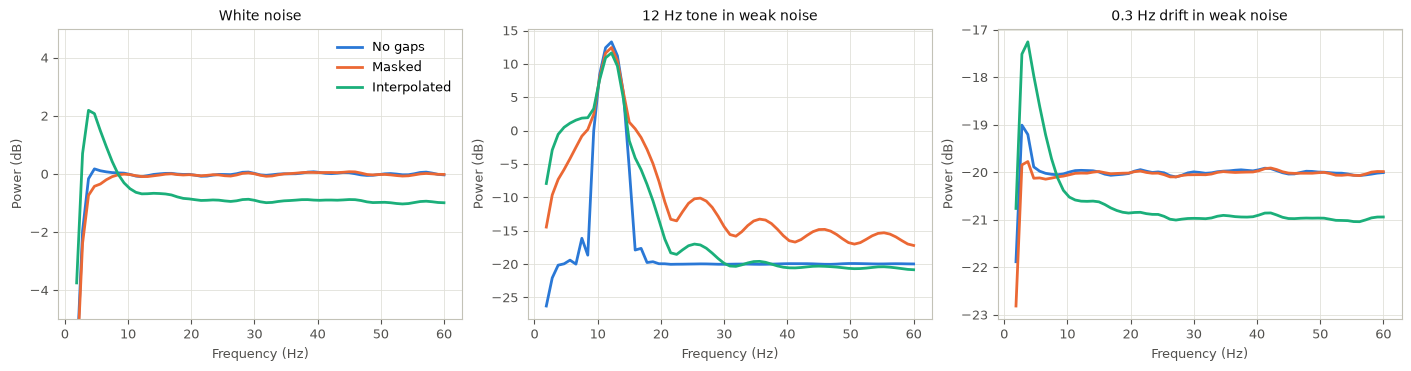

In [13]:
WINDOW = np.hanning(WINDOW_SAMPLES + 2)[1:-1].astype(np.float32)
FREQUENCIES = np.fft.rfftfreq(FFT_SAMPLES, 1 / SAMPLE_RATE)
SHOWN = FREQUENCIES >= LOWEST_HZ


def interpolate(values: np.ndarray) -> np.ndarray:
    """Fill missing samples linearly; used only for the gap check."""
    result = values.copy()
    positions = np.arange(len(values))
    for column in range(values.shape[1]):
        valid = np.isfinite(values[:, column])
        result[:, column] = np.interp(
            positions, positions[valid], values[valid, column]
        )
    return result


def masked_stft(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return masked STFT power ``[frame, frequency, series]`` and frame centres.

    Missing samples (NaN) have weight zero. White noise of variance s has an
    expected power of s at every frequency, whatever its gaps. Frames with fewer
    than ``MINIMUM_VALID`` valid samples are NaN.

    Args:
        values: Samples ``[time, series]``; NaN marks missing samples.

    Returns:
        Power, and each frame's centre in samples.
    """
    valid = np.isfinite(values)
    filled = np.where(valid, values, 0).astype(np.float32)
    starts = np.arange(0, len(values) - WINDOW_SAMPLES + 1, HOP_SAMPLES)
    view = np.lib.stride_tricks.sliding_window_view
    frames = view(filled, WINDOW_SAMPLES, axis=0)[starts]
    present = view(valid, WINDOW_SAMPLES, axis=0)[starts]
    weight = present * WINDOW
    # Weighted linear trend per frame and series.
    position = np.arange(WINDOW_SAMPLES, dtype=np.float32) - (WINDOW_SAMPLES - 1) / 2
    total = np.maximum(weight.sum(-1), 1e-6)
    centre = (weight * position).sum(-1) / total
    mean = (weight * frames).sum(-1) / total
    offset = position - centre[..., None]
    spread = np.maximum((weight * offset**2).sum(-1), 1e-6)
    slope = (weight * offset * frames).sum(-1) / spread
    tapered = (frames - mean[..., None] - slope[..., None] * offset) * weight
    transformed = scipy_fft.rfft(tapered, FFT_SAMPLES, axis=-1)
    norm = np.maximum((weight**2).sum(-1), 1e-6)
    power = np.abs(transformed) ** 2 / norm[..., None]
    power[present.mean(-1) < MINIMUM_VALID] = np.nan
    return power.transpose(0, 2, 1), starts + WINDOW_SAMPLES / 2


example_rows = segments[EXAMPLE_DATASET].filter(
    pl.col("activity_label") == EXAMPLE_ACTIVITY
)
if EXAMPLE_SEGMENT is not None:
    example_rows = example_rows.filter(pl.col("segment_id") == EXAMPLE_SEGMENT)
example = example_rows.sort("segment_id").row(0, named=True)
with read_segment(
    EXPORT / EXAMPLE_DATASET / "segments" / example["segment_id"]
) as saved:
    receiver_mask = np.isfinite(saved["filtered_amplitude"]).mean(axis=2) > 0.5
for index, receiver in enumerate(RECEIVERS):
    edges = np.flatnonzero(np.diff(np.r_[0, ~receiver_mask[:, index], 0]))
    lengths = edges[1::2] - edges[::2]
    print(
        f"{receiver}: {(~receiver_mask[:, index]).mean():.1%} missing, "
        f"{(lengths == 12).sum()} gaps of 12 samples, {(lengths != 12).sum()} others"
    )

generator = np.random.default_rng(42)
samples = len(receiver_mask)
seconds = np.arange(samples) / SAMPLE_RATE
phases = generator.uniform(0, 2 * np.pi, 200)
synthetic = {
    "White noise": generator.normal(size=(samples, 200)),
    "12 Hz tone in weak noise": np.sqrt(2)
    * np.sin(2 * np.pi * 12 * seconds[:, None] + phases)
    + 0.1 * generator.normal(size=(samples, 200)),
    "0.3 Hz drift in weak noise": np.sqrt(2)
    * np.sin(2 * np.pi * 0.3 * seconds[:, None] + phases)
    + 0.1 * generator.normal(size=(samples, 200)),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout="constrained")
for ax, (title, signal) in zip(axes, synthetic.items()):
    gapped = np.where(receiver_mask[:, :1], signal, np.nan)
    for color, label, values in zip(
        SERIES,
        ("No gaps", "Masked", "Interpolated"),
        (signal, gapped, interpolate(gapped)),
    ):
        power = np.nanmean(masked_stft(values)[0], axis=(0, 2))
        ax.plot(
            FREQUENCIES[SHOWN],
            10 * np.log10(power[SHOWN]),
            color=color,
            lw=2,
            label=label,
        )
    ax.set(title=title, xlabel="Frequency (Hz)", ylabel="Power (dB)")
    ax.grid(color=GRID, lw=0.6)
axes[0].set(ylim=(-5, 5))
axes[0].legend(frameon=False)
plt.show()

## Loading and transforming an attempt

Each tone's STFT power is computed separately, converted to dB, and then averaged over a receiver's 245 tones. Two other averages hide the activity:

- Averaging the *signals* first cancels motion, because tones respond with different signs.
- Averaging *power* lets a few noisy tones decide the result. For the squared difference this matters most, because its power grows with the fourth power of the amplitude.

Averaging dB also turns each tone's gain into a constant, which the quiet reference removes, so amplitudes need no scaling. The quiet reference is each receiver's median spectrum over the frames that end before the action cue (the `preparation` phase). A participant may already be moving then, notably before walking activities.

In [14]:
def signed_difference(values: np.ndarray) -> np.ndarray:
    """Change between consecutive samples; NaN where either is missing."""
    result = np.full_like(values, np.nan)
    result[1:] = values[1:] - values[:-1]
    return result


def load_attempt(dataset: str, segment_id: str) -> dict:
    """Read one attempt's signals, its phases and its main burst."""
    with read_segment(EXPORT / dataset / "segments" / segment_id) as saved:
        amplitude = np.asarray(saved["filtered_amplitude"], dtype=np.float32)
        squared = np.asarray(saved["squared_difference"], dtype=np.float32)
        phase = np.asarray(saved["phase"])
    signals = {
        "squared_difference": squared,
        "signed_difference": signed_difference(amplitude),
        "filtered_amplitude": amplitude,
    }
    burst = main_burst(motion_envelope(amplitude), phase, rate_hz=SAMPLE_RATE)
    return {"signals": signals, "phase": phase, "burst": burst}


def spectrogram(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return the mean over tones of STFT power in dB, and frame centres.

    Args:
        values: Samples ``[time, receiver, tone]``.

    Returns:
        Decibels ``[frame, frequency, receiver]``, and each frame's centre in samples.
    """
    time, receivers, tones = values.shape
    power, centres = masked_stft(values.reshape(time, -1))
    decibels = 10 * np.log10(np.maximum(power, 1e-12))
    decibels = decibels.reshape(len(centres), len(FREQUENCIES), receivers, tones)
    return np.nanmean(decibels, axis=3), centres


def change_db(decibels: np.ndarray, centres: np.ndarray, cue: int) -> np.ndarray:
    """Decibels over each receiver's median spectrum before the action cue."""
    quiet = centres + WINDOW_SAMPLES / 2 <= cue
    return decibels - np.nanmedian(decibels[quiet], axis=0)


def cue_bounds(phase: np.ndarray) -> tuple[int, int]:
    """First sample and end (exclusive) of the action cue."""
    action = np.flatnonzero(phase == "action")
    return int(action[0]), int(action[-1]) + 1


attempt = load_attempt(EXAMPLE_DATASET, example["segment_id"])
cue_start, cue_end = cue_bounds(attempt["phase"])
print(
    f"Example: {EXAMPLE_DATASET} · {EXAMPLE_ACTIVITY} · {example['scenario_id']} · "
    f"segment {example['segment_id']} · {len(attempt['phase']) / SAMPLE_RATE:.1f} s"
)

Example: akmal · walk_to_fall · walk-to-fall__start_front__end_front · segment 169-01-000 · 13.3 s


In [15]:
def draw(ax, image, centres, origin, colormap, limits):
    """Draw one spectrogram with time in seconds from a sample index."""
    half = HOP_SAMPLES / 2
    left = (centres[0] - half - origin) / SAMPLE_RATE
    right = (centres[-1] + half - origin) / SAMPLE_RATE
    step = FREQUENCIES[1] / 2
    shown = FREQUENCIES[SHOWN]
    return ax.imshow(
        np.ma.masked_invalid(image[:, SHOWN].T),
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        extent=(left, right, shown[0] - step, shown[-1] + step),
        cmap=colormap,
        vmin=limits[0],
        vmax=limits[1],
    )


def show_attempt(name: str) -> None:
    """Plot one signal of the example attempt: trace and spectrograms per receiver."""
    values = attempt["signals"][name]
    decibels, centres = spectrogram(values)
    change = change_db(decibels, centres, cue_start)
    limits = tuple(np.nanquantile(decibels[:, SHOWN], (0.02, 0.995)))
    bound = float(np.nanquantile(np.abs(change[:, SHOWN]), 0.995))
    fig, axes = plt.subplots(
        5,
        2,
        figsize=(14, 12),
        sharex=True,
        layout="constrained",
        gridspec_kw={"height_ratios": (0.7, 1, 1, 1, 1)},
    )
    # The model reads log1p of the squared difference. Tones move in opposite
    # directions, so the amplitude is shown as its distance from each tone's
    # attempt median.
    if name == "squared_difference":
        shown, unit = np.log1p(values), "log1p(squared difference)"
    elif name == "signed_difference":
        shown, unit = np.abs(values), "|signed difference|"
    else:
        shown = np.abs(values - np.nanmedian(values, axis=0))
        unit = "|amplitude − median|"
    trace = np.nanmean(shown, axis=(1, 2))
    broadband = np.nanmean(change[:, SHOWN], axis=(1, 2))
    time = (np.arange(len(values)) - cue_start) / SAMPLE_RATE
    axes[0, 0].plot(time, trace, lw=0.8, color=SERIES[0])
    axes[0, 0].set(title=f"Time domain: {unit}, mean over tones and receivers")
    axes[0, 1].plot(
        (centres - cue_start) / SAMPLE_RATE, broadband, lw=2, color=SERIES[0]
    )
    axes[0, 1].set(title="Change, mean over frequencies and receivers", ylabel="dB")
    for r, receiver in enumerate(RECEIVERS):
        left = draw(
            axes[r + 1, 0], decibels[..., r], centres, cue_start, SEQUENTIAL, limits
        )
        right = draw(
            axes[r + 1, 1],
            change[..., r],
            centres,
            cue_start,
            DIVERGING,
            (-bound, bound),
        )
        axes[r + 1, 0].set(ylabel=f"{receiver}\nFrequency (Hz)")
    axes[1, 0].set(title="Power, mean of tone dB")
    axes[1, 1].set(title="Change from the quiet reference")
    for ax in axes.flat:
        for edge in (cue_start, cue_end):
            ax.axvline((edge - cue_start) / SAMPLE_RATE, color=INK, lw=0.9, ls="--")
        if attempt["burst"] is not None:
            peak = (attempt["burst"]["peak"] - cue_start) / SAMPLE_RATE
            ax.axvline(peak, color=INK, lw=0.9, ls=":")
    for ax in axes[-1]:
        ax.set(
            xlabel="Time from action cue (s); dashed: cue start and end, dotted: main burst"
        )
    fig.colorbar(left, ax=axes[1:, 0], label="Power (dB)", shrink=0.6)
    fig.colorbar(right, ax=axes[1:, 1], label="Change (dB)", shrink=0.6)
    fig.suptitle(
        f"{SIGNALS[name]} · {EXAMPLE_DATASET} · {EXAMPLE_ACTIVITY} · {example['segment_id']}"
    )
    plt.show()

## Squared difference: STFT and spectrogram

Left: power per receiver. Right: the same power relative to that receiver's quiet spectrum, which removes the noise floor and shows what the activity adds.

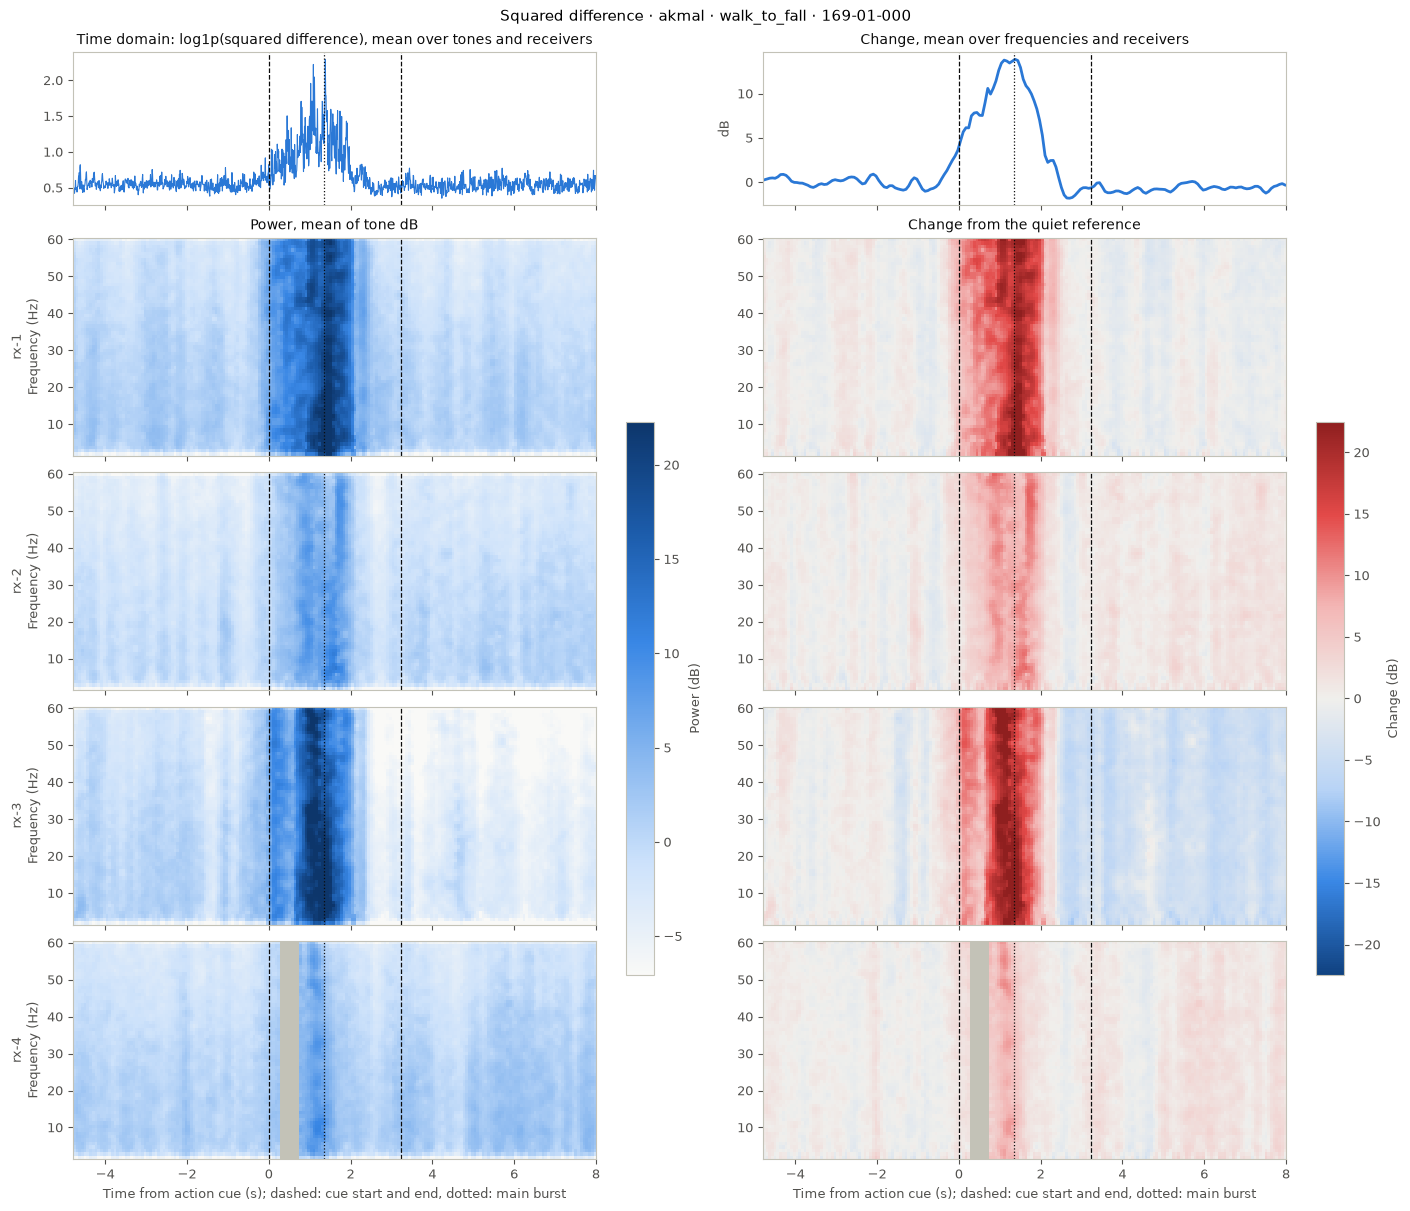

In [16]:
show_attempt("squared_difference")

## Hampel-filtered amplitude: STFT and spectrogram

The same steps on the filtered amplitude itself.

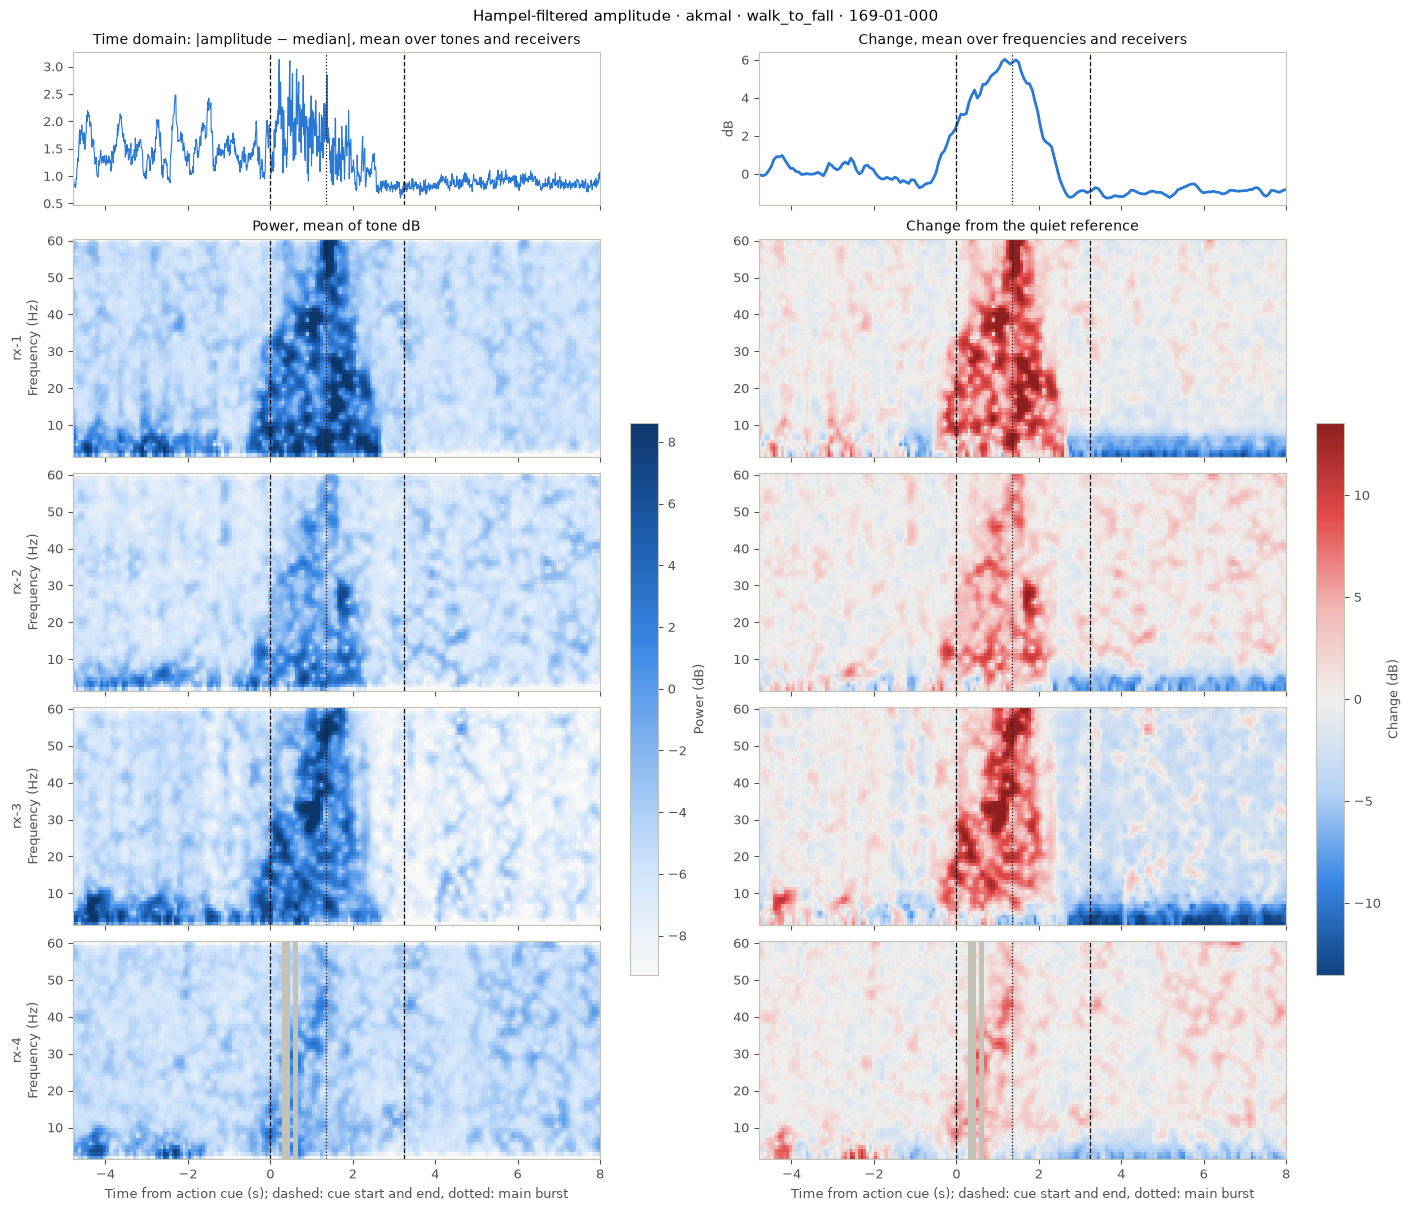

In [17]:
show_attempt("filtered_amplitude")

## Signed difference: STFT and spectrogram

The change before squaring. Differencing multiplies the power at frequency $f$ by $4\sin^2(\pi f/120)$: 0.27 at 10 Hz, 2 at 30 Hz and 4 at 60 Hz. The left panels therefore lose their slow part, but the factor is the same in quiet and in motion and nearly cancels in the right panels. Unlike the filtered amplitude, the signed difference has no static level, which is what identified a session in that input ([generalization report](../../docs/reports/generalization-2026-11-22.md)), and no gap filling is needed to compute it.

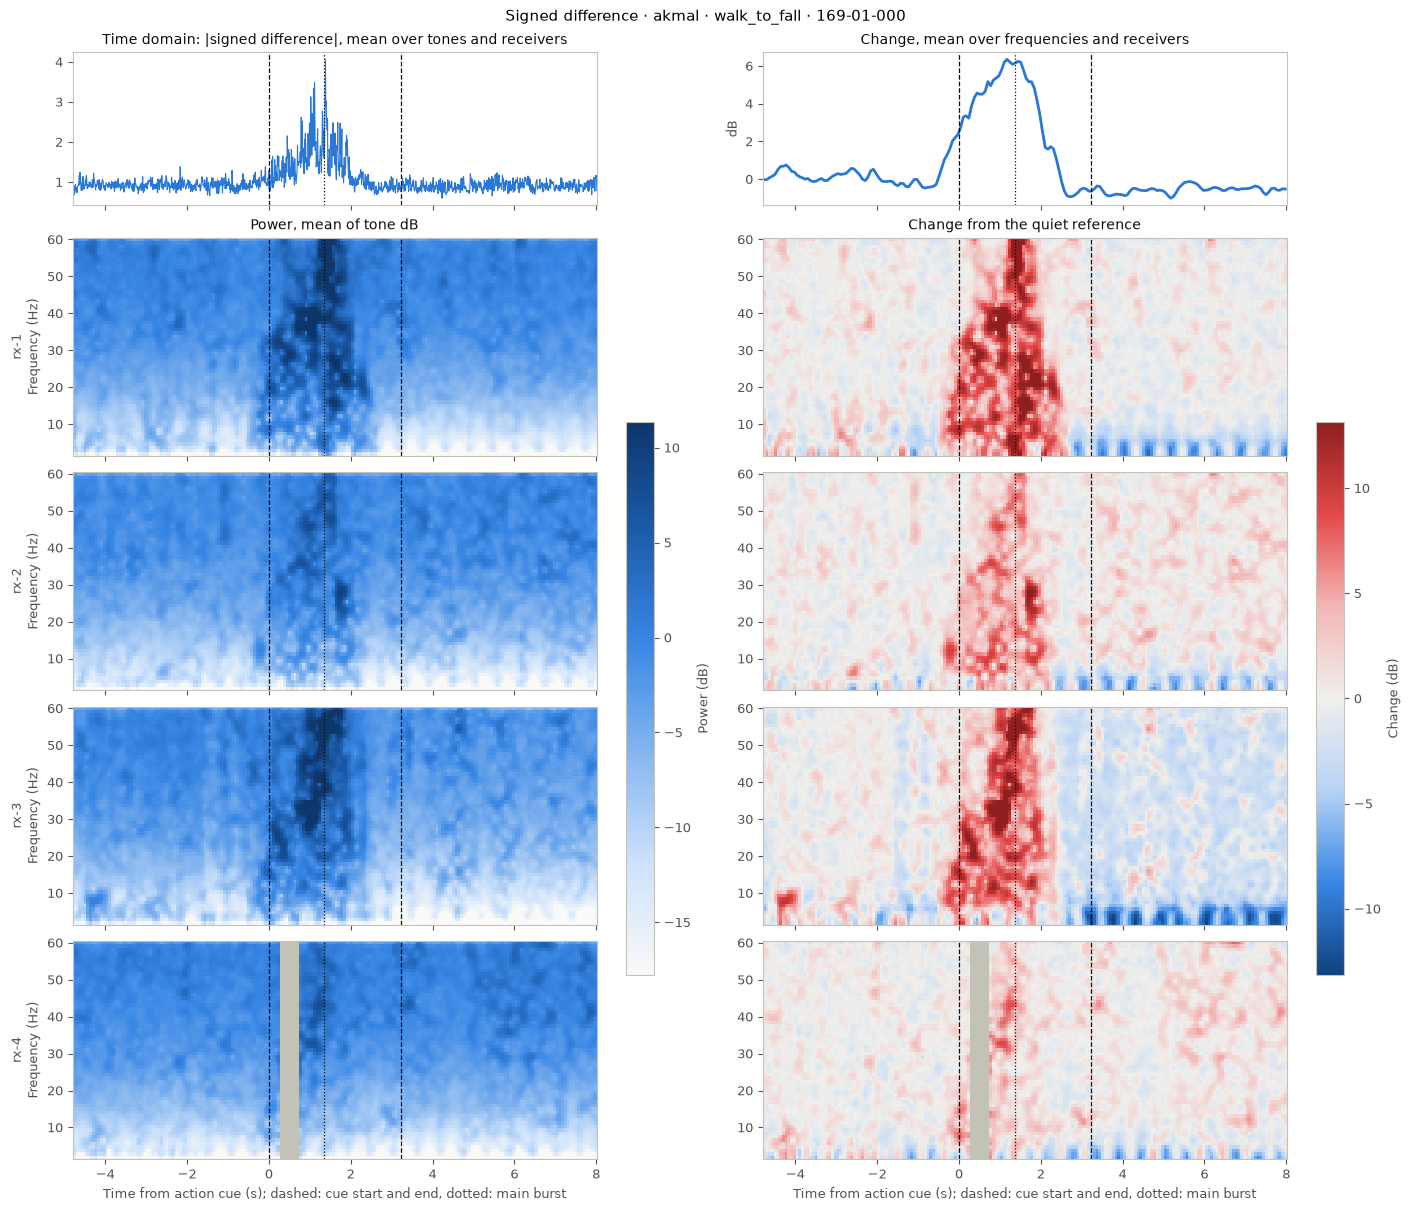

In [18]:
show_attempt("signed_difference")

## One attempt of every activity

The first attempt of each activity, averaged over receivers, relative to its quiet reference. Each signal has its own colour scale: squaring roughly doubles a change in dB. The attempts are the first recorded, not chosen by appearance.

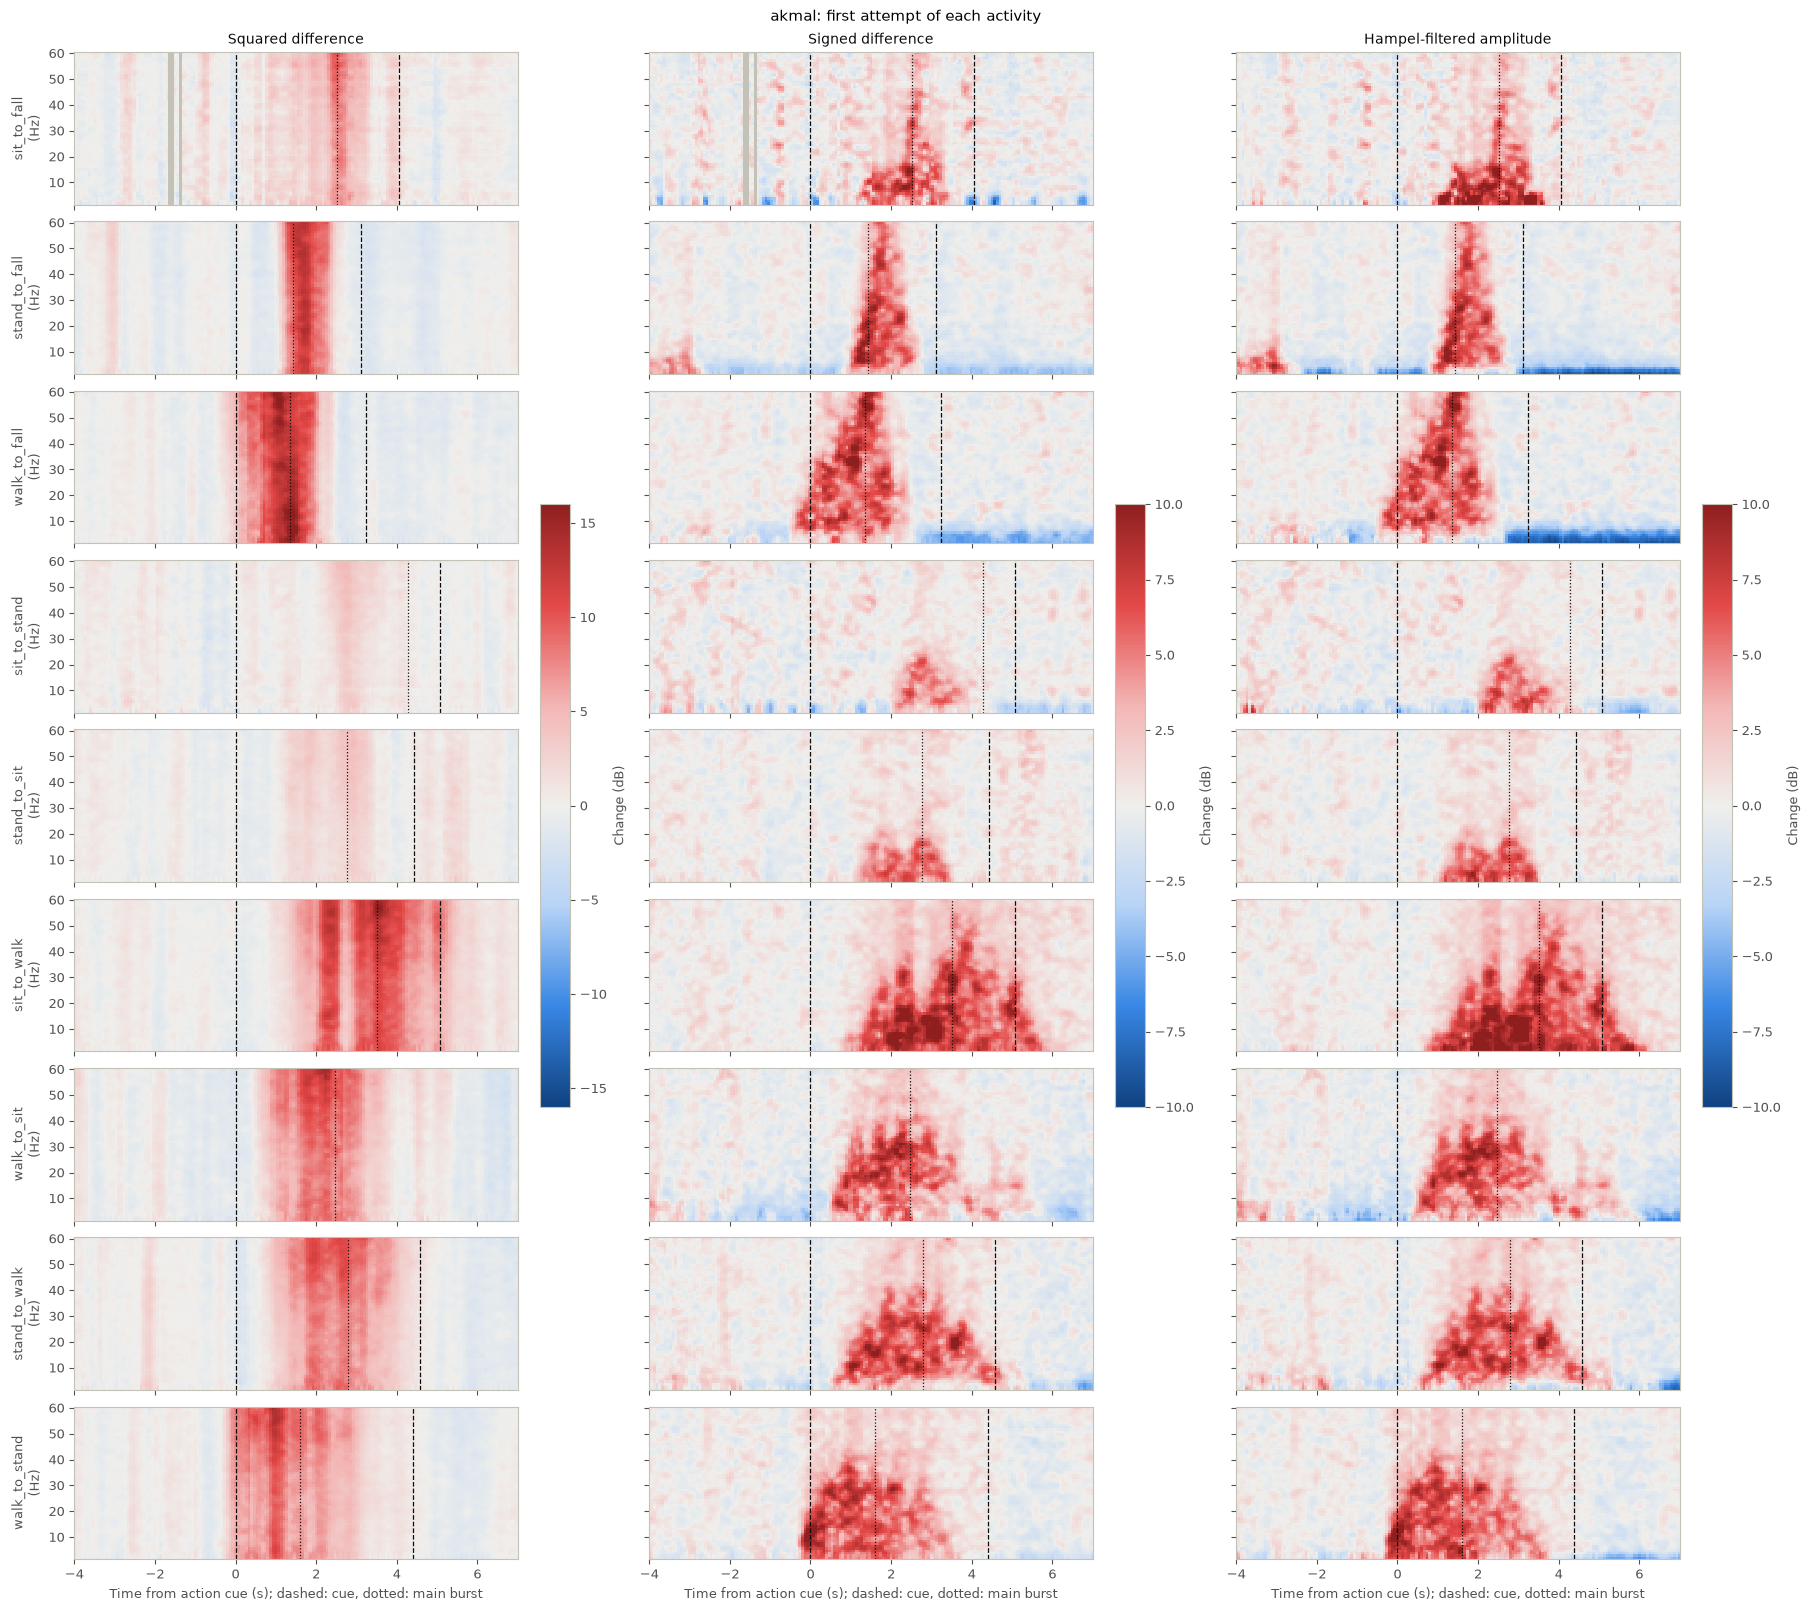

In [19]:
fig, axes = plt.subplots(
    len(FALLS + TRANSITIONS),
    len(SIGNALS),
    figsize=(18, 16),
    sharex=True,
    sharey=True,
    layout="constrained",
)
for row, activity in enumerate(FALLS + TRANSITIONS):
    record = (
        segments[EXAMPLE_DATASET]
        .filter(pl.col("activity_label") == activity)
        .sort("segment_id")
        .row(0, named=True)
    )
    loaded = load_attempt(EXAMPLE_DATASET, record["segment_id"])
    start, end = cue_bounds(loaded["phase"])
    for column, (name, label) in enumerate(SIGNALS.items()):
        decibels, centres = spectrogram(loaded["signals"][name])
        image = np.nanmean(change_db(decibels, centres, start), axis=2)
        bound = LIMITS[name][0]
        ax = axes[row, column]
        drawn = draw(ax, image, centres, start, DIVERGING, (-bound, bound))
        ax.set(xlim=(-4, 7))
        for edge in (start, end):
            ax.axvline((edge - start) / SAMPLE_RATE, color=INK, lw=0.9, ls="--")
        if loaded["burst"] is not None:
            peak = (loaded["burst"]["peak"] - start) / SAMPLE_RATE
            ax.axvline(peak, color=INK, lw=0.9, ls=":")
        if row == 0:
            ax.set(title=label)
            fig.colorbar(drawn, ax=axes[:, column], label="Change (dB)", shrink=0.4)
        if column == 0:
            ax.set(ylabel=f"{activity}\n(Hz)")
        if row == len(FALLS + TRANSITIONS) - 1:
            ax.set(xlabel="Time from action cue (s); dashed: cue, dotted: main burst")
fig.suptitle(f"{EXAMPLE_DATASET}: first attempt of each activity")
plt.show()

## Average over all attempts

Every attempt is aligned at its main burst, the strongest motion peak around the action cue, found by the same rule for falls and transitions. Averaging keeps what repeats between attempts and blurs what does not. The burst is less certain for weak movements such as sitting down, so their averages are blurred more.

In [20]:
ALIGN_SECONDS = 3
HALF_FRAMES = ALIGN_SECONDS * SAMPLE_RATE // HOP_SAMPLES
OFFSETS = np.arange(-HALF_FRAMES, HALF_FRAMES + 1) * HOP_SAMPLES / SAMPLE_RATE
BANDS_HZ = ((2, 10), (10, 20), (20, 30), (30, 45), (45, 61), (2, 61))
BANDS = [
    SHOWN & (FREQUENCIES >= low - 0.2) & (FREQUENCIES < high) for low, high in BANDS_HZ
]
# The peak of a band is this quantile over the frames of the cue window, which
# runs from 0.5 s before the action cue to 1 s after it.
PEAK_QUANTILE = 0.9


def summarize(job: tuple[str, str]) -> dict | None:
    """Return an attempt's burst-aligned change and band peaks per signal."""
    loaded = load_attempt(*job)
    if loaded["burst"] is None:
        return None
    start, end = cue_bounds(loaded["phase"])
    result = {}
    for name, values in loaded["signals"].items():
        decibels, centres = spectrogram(values)
        # Half-up rounding: rint would send two frames to one slot when the
        # burst lies midway between frames.
        frame = np.floor(
            (centres - loaded["burst"]["peak"]) / HOP_SAMPLES + 0.5
        ).astype(int)
        inside = np.abs(frame) <= HALF_FRAMES
        cue = (centres >= start - SAMPLE_RATE / 2) & (centres <= end + SAMPLE_RATE)
        image = np.full((len(OFFSETS), len(FREQUENCIES)), np.nan, dtype=np.float32)
        change = np.nanmean(change_db(decibels, centres, start), axis=2)
        image[frame[inside] + HALF_FRAMES] = change[inside]
        peaks = [
            np.nanquantile(np.nanmean(change[cue][:, band], axis=1), PEAK_QUANTILE)
            for band in BANDS
        ]
        result[name] = {"image": image, "peaks": peaks}
    return result


aligned = {}  # (dataset, signal) -> [attempt, frame, frequency]
peaks = {}  # (dataset, signal) -> [attempt, band]
labels = {}  # dataset -> activity of each attempt
identifiers = {}  # dataset -> segment ID of each attempt
with ThreadPoolExecutor(THREADS) as pool:
    for dataset in DATASETS:
        records = segments[dataset].sort("segment_id")
        found = list(
            pool.map(
                summarize, [(dataset, segment) for segment in records["segment_id"]]
            )
        )
        kept = [index for index, item in enumerate(found) if item is not None]
        labels[dataset] = records["activity_label"].to_numpy()[kept]
        identifiers[dataset] = records["segment_id"].to_numpy()[kept]
        for name in SIGNALS:
            aligned[dataset, name] = np.stack([found[i][name]["image"] for i in kept])
            peaks[dataset, name] = np.array([found[i][name]["peaks"] for i in kept])
        print(f"{dataset}: {len(kept)} of {len(records)} attempts have a main burst")

khaelano: 232 of 232 attempts have a main burst
akmal: 231 of 231 attempts have a main burst


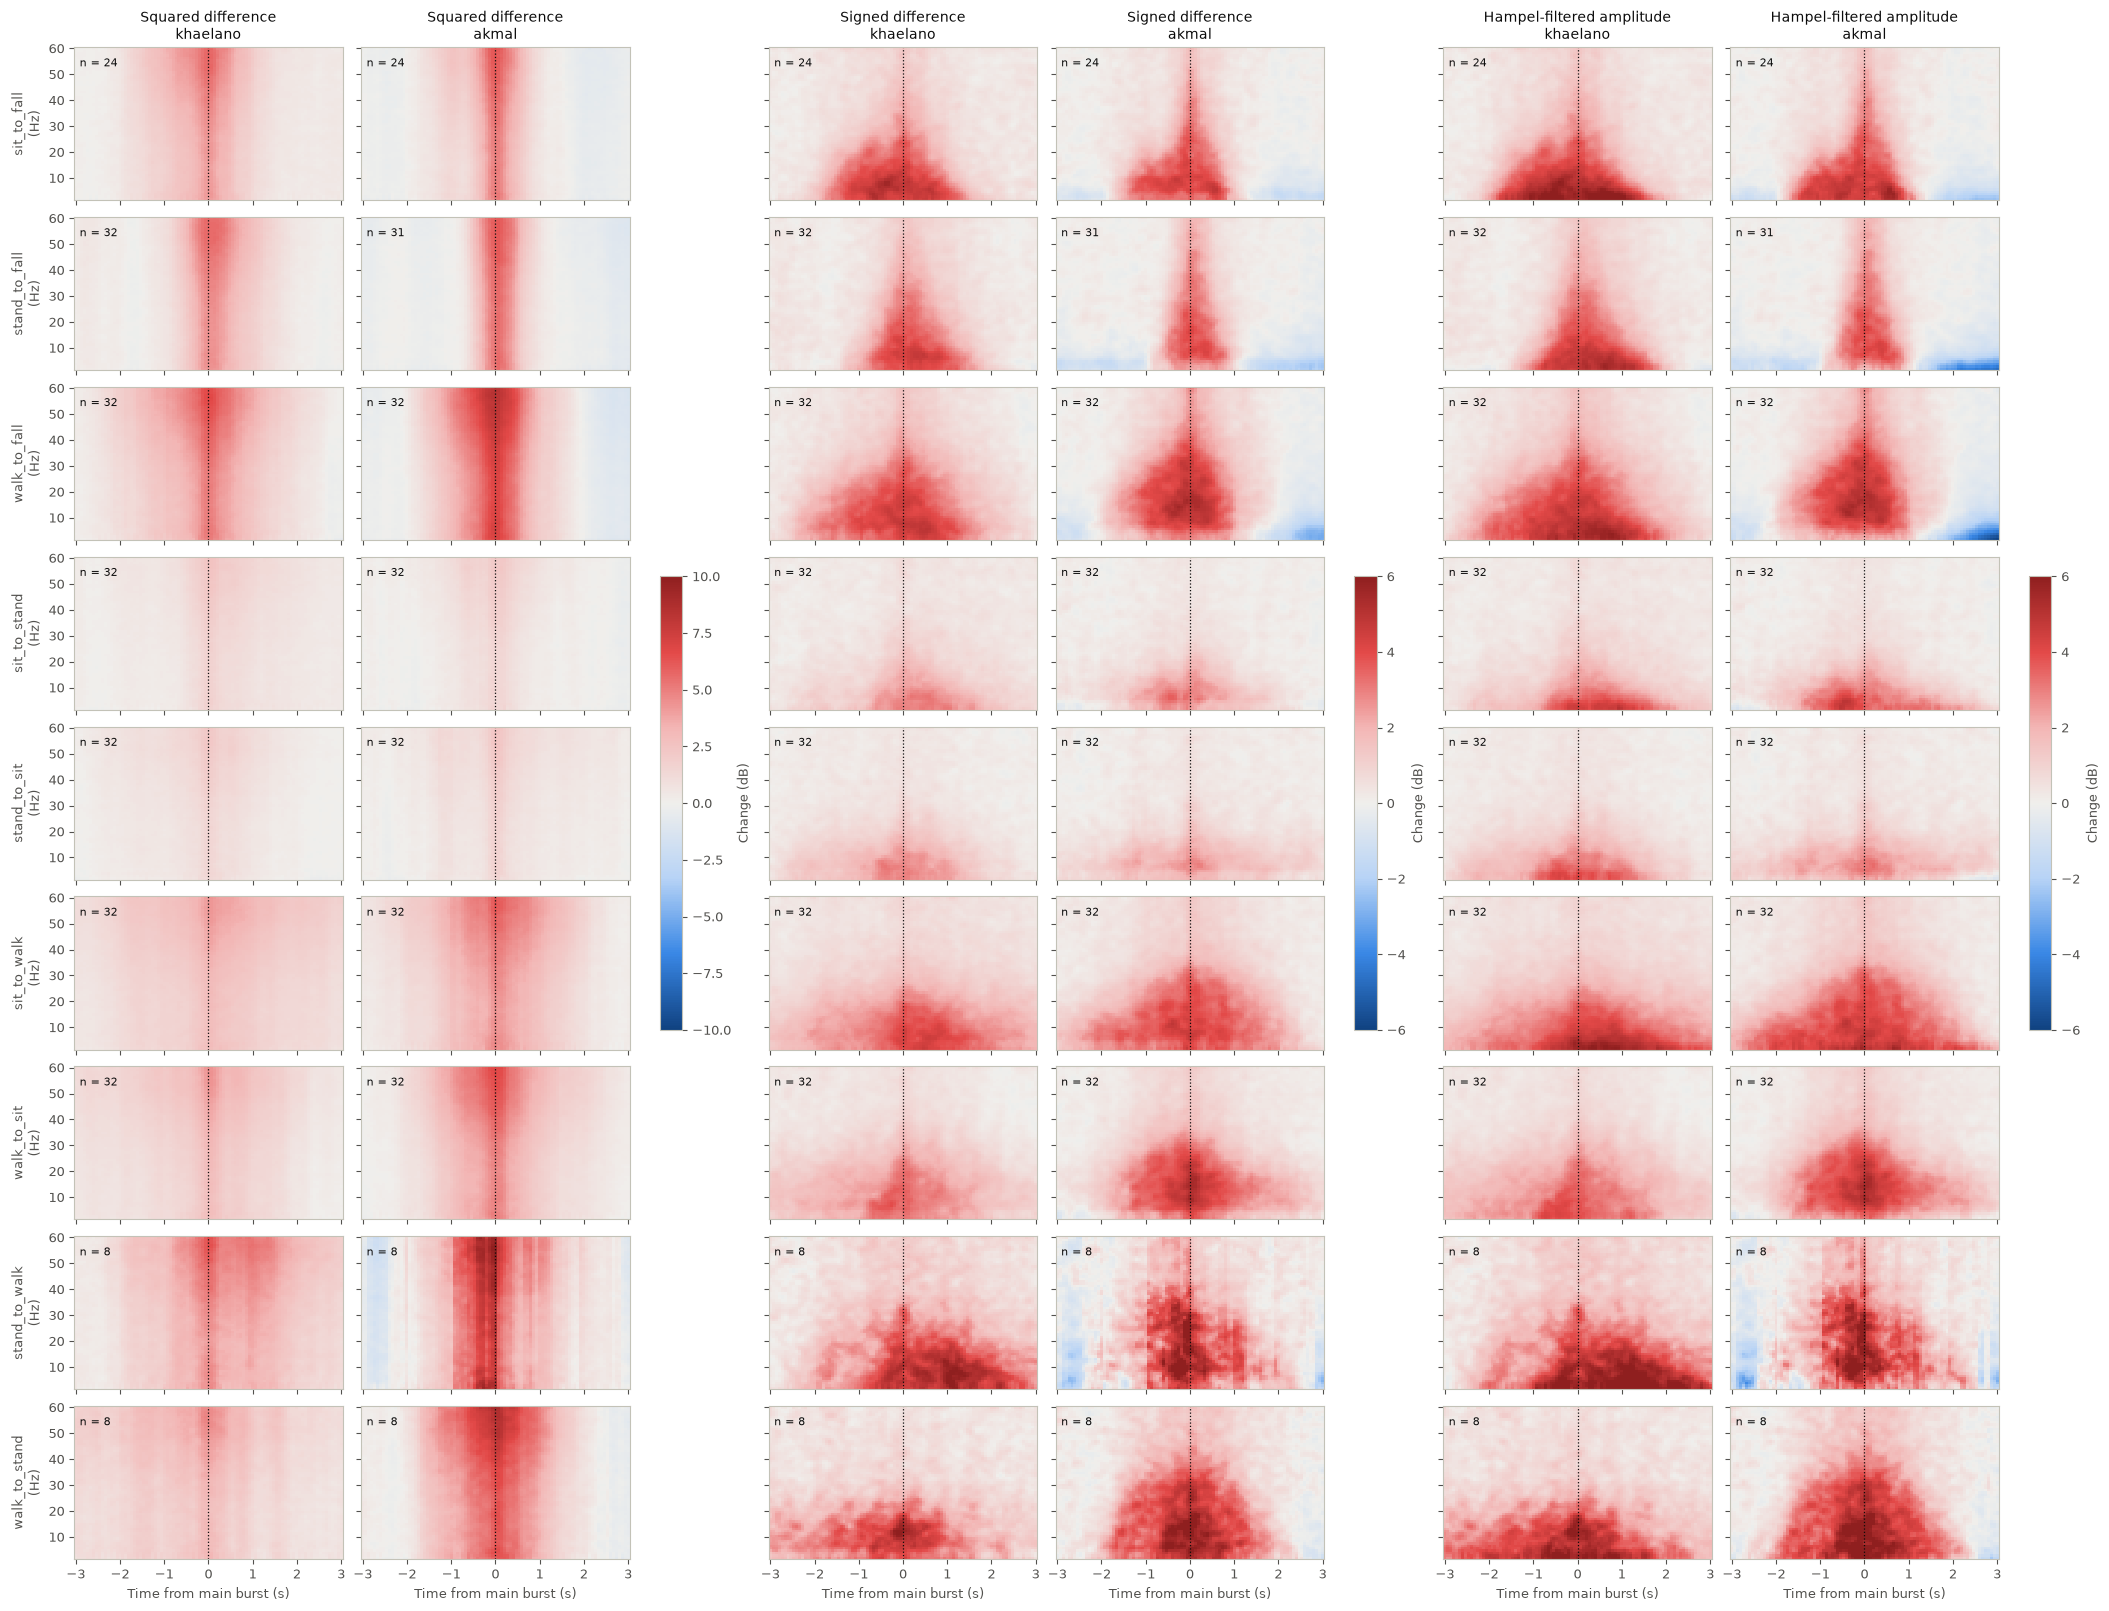

In [21]:
fig, axes = plt.subplots(
    len(FALLS + TRANSITIONS),
    2 * len(SIGNALS),
    figsize=(21, 16),
    sharex=True,
    sharey=True,
    layout="constrained",
)
panels = [(name, dataset) for name in SIGNALS for dataset in DATASETS]
for column, (name, dataset) in enumerate(panels):
    bound = LIMITS[name][1]
    for row, activity in enumerate(FALLS + TRANSITIONS):
        chosen = labels[dataset] == activity
        image = np.nanmean(aligned[dataset, name][chosen], axis=0)
        ax = axes[row, column]
        drawn = draw(ax, image, OFFSETS * SAMPLE_RATE, 0, DIVERGING, (-bound, bound))
        ax.axvline(0, color=INK, lw=0.9, ls=":")
        ax.text(
            0.02,
            0.93,
            f"n = {chosen.sum()}",
            transform=ax.transAxes,
            va="top",
            color=INK,
            fontsize=8,
        )
        if row == 0:
            ax.set(title=f"{SIGNALS[name]}\n{dataset}")
        if column == 0:
            ax.set(ylabel=f"{activity}\n(Hz)")
        if row == len(FALLS + TRANSITIONS) - 1:
            ax.set(xlabel="Time from main burst (s)")
    if column % 2:
        fig.colorbar(
            drawn, ax=axes[:, column - 1 : column + 1], label="Change (dB)", shrink=0.3
        )
plt.show()

## Why the squared difference is flat

The change over quiet within ±0.25 s of the main burst, averaged over all falls and divided by its own mean over frequency, so a perfectly flat bar lies on 1. If shuffling the samples in time leaves a curve's height and shape alone, the spectrogram reports how large the values are, not when they occur.

Squaring creates every sum and difference of the frequencies present, and those above 60 Hz fold back. It also turns noise-like changes into nearly uncorrelated spikes, whose spectrum is flat. Motion makes the spikes larger, so all frequencies rise together.

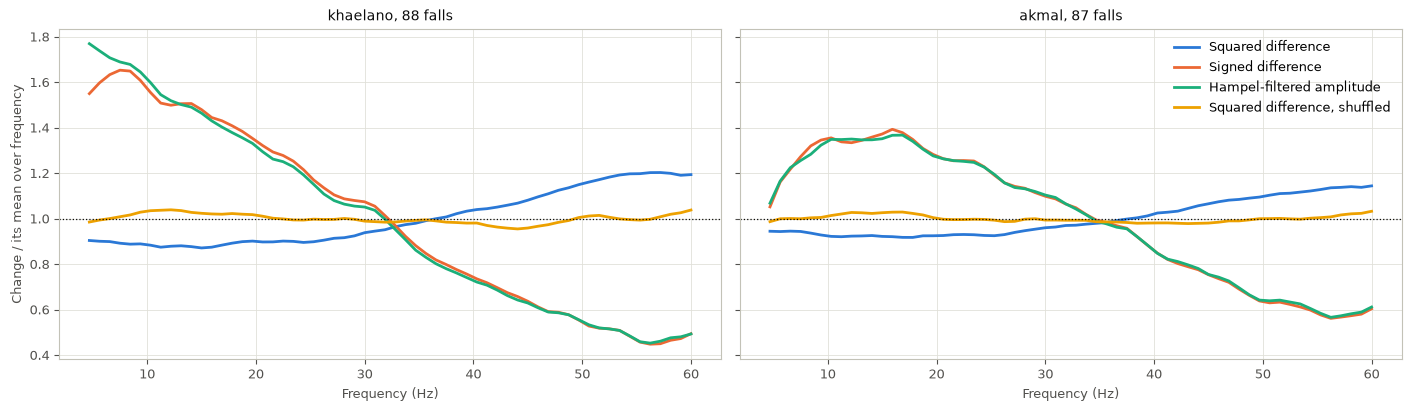

dataset,signal,mean change (dB),range over frequency (dB),range / mean
str,str,f64,f64,f64
"""khaelano""","""Squared difference""",4.82,1.6,0.33
"""khaelano""","""Signed difference""",2.81,3.38,1.21
"""khaelano""","""Hampel-filtered amplitude""",2.92,3.85,1.32
"""khaelano""","""Squared difference, shuffled""",4.67,0.39,0.08
"""akmal""","""Squared difference""",5.84,1.32,0.23
"""akmal""","""Signed difference""",3.19,2.65,0.83
"""akmal""","""Hampel-filtered amplitude""",3.21,2.57,0.8
"""akmal""","""Squared difference, shuffled""",5.71,0.31,0.05


In [22]:
SHUFFLE_SAMPLES = 16
CLOSE = np.abs(OFFSETS) <= 0.25


def shuffled_change(job: tuple[str, str]) -> np.ndarray:
    """Change at the burst of a squared difference shuffled in time.

    Received samples are permuted within blocks of ``SHUFFLE_SAMPLES``, which
    keeps their sizes, the gaps and the slow envelope but destroys the order.
    """
    loaded = load_attempt(*job)
    values = loaded["signals"]["squared_difference"].copy()
    generator = np.random.default_rng(42)
    for block in range(0, len(values) - SHUFFLE_SAMPLES + 1, SHUFFLE_SAMPLES):
        received = np.isfinite(values[block : block + SHUFFLE_SAMPLES]).any(axis=(1, 2))
        rows = np.flatnonzero(received) + block
        values[rows] = values[generator.permutation(rows)]
    decibels, centres = spectrogram(values)
    start, _ = cue_bounds(loaded["phase"])
    change = np.nanmean(change_db(decibels, centres, start), axis=2)
    close = np.abs(centres - loaded["burst"]["peak"]) <= 0.25 * SAMPLE_RATE
    return np.nanmean(change[close], axis=0)


flatness = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, layout="constrained")
for ax, dataset in zip(axes, DATASETS):
    falls = np.isin(labels[dataset], FALLS)
    jobs = [(dataset, segment) for segment in identifiers[dataset][falls]]
    with ThreadPoolExecutor(THREADS) as pool:
        shuffled = list(pool.map(shuffled_change, jobs))
    spectra = {
        label: np.nanmean(aligned[dataset, name][falls][:, CLOSE], axis=(0, 1))
        for name, label in SIGNALS.items()
    }
    spectra["Squared difference, shuffled"] = np.nanmean(shuffled, axis=0)
    # Bins below 4 Hz are dominated by the per-frame detrend.
    used = FREQUENCIES >= 4
    for color, (label, change) in zip(SERIES, spectra.items()):
        relative = change[used] / change[used].mean()
        ax.plot(FREQUENCIES[used], relative, color=color, lw=2, label=label)
        flatness.append(
            {
                "dataset": dataset,
                "signal": label,
                "mean change (dB)": round(float(change[used].mean()), 2),
                "range over frequency (dB)": round(float(np.ptp(change[used])), 2),
                "range / mean": round(float(np.ptp(relative)), 2),
            }
        )
    ax.axhline(1, color=INK, lw=0.9, ls=":")
    ax.grid(color=GRID, lw=0.6)
    ax.set(title=f"{dataset}, {falls.sum()} falls", xlabel="Frequency (Hz)")
axes[0].set(ylabel="Change / its mean over frequency")
axes[1].legend(frameon=False)
plt.show()
display(pl.DataFrame(flatness))

## Where falls differ from transitions

For every time-frequency cell, the area under the ROC curve (AUC) of that cell's change for separating the two classes: above 0.5 falls are stronger, below 0.5 transitions are. The last column keeps only what both sessions agree on (the AUC closer to 0.5 when both lie on the same side). No model is trained. With roughly 88 falls and 144 transitions per session a single cell's AUC has a standard error of about 0.04, so isolated cells mean nothing; only areas that repeat in both sessions do.

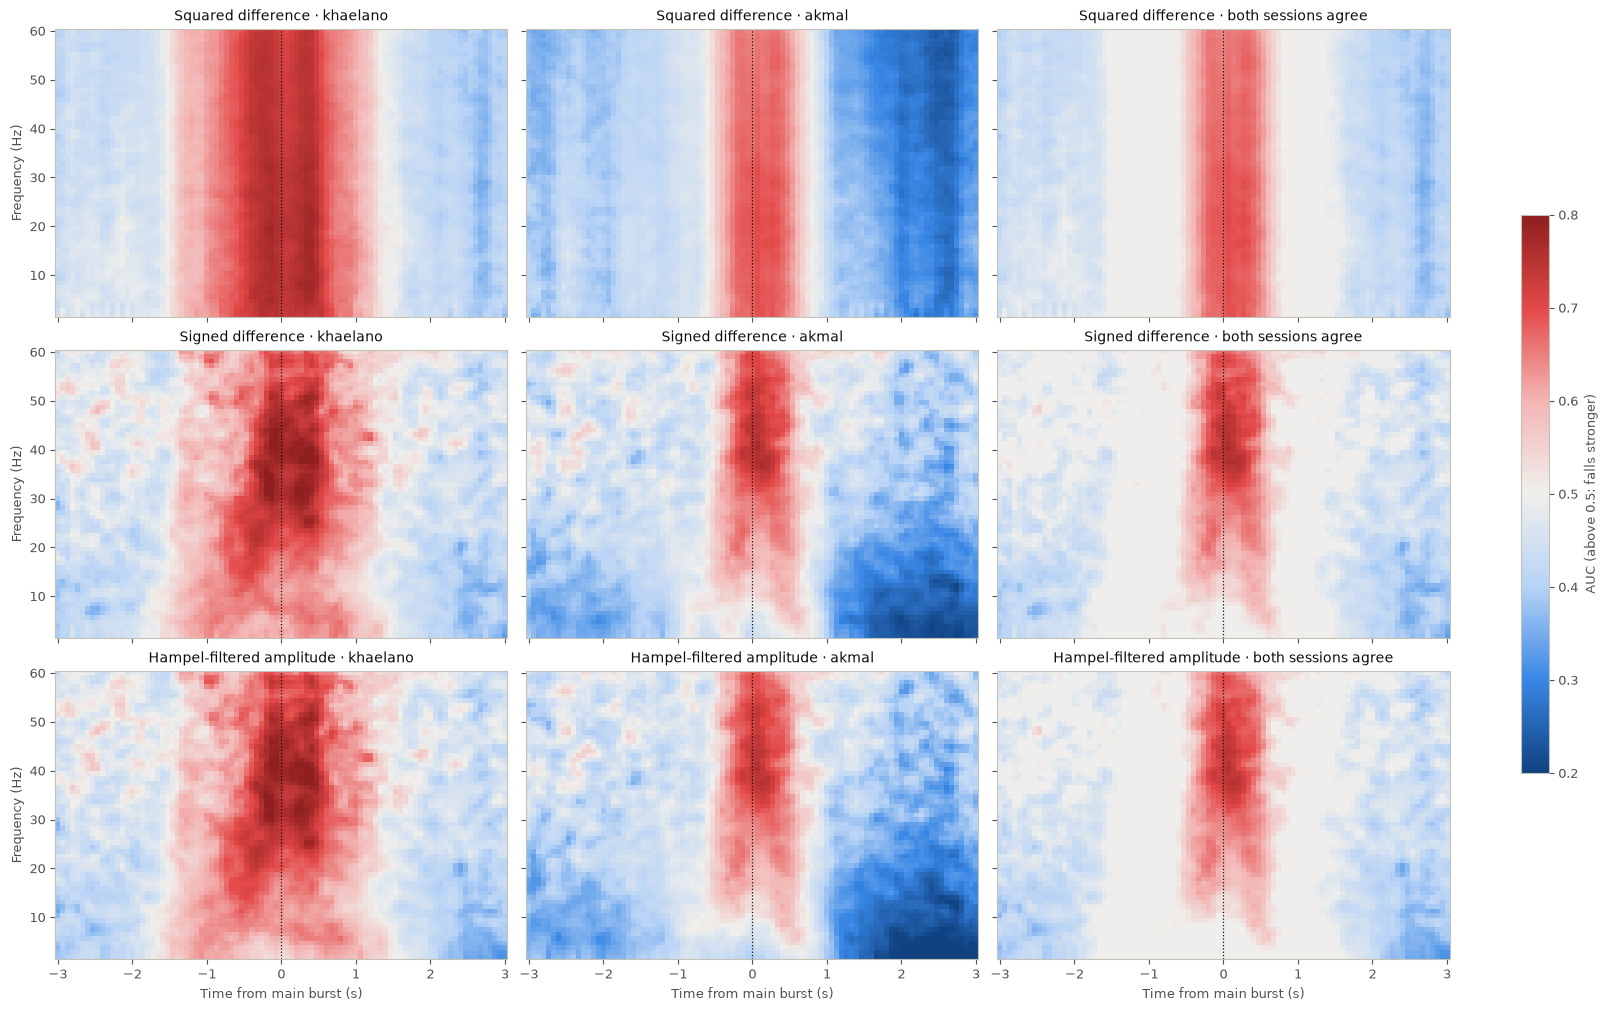

In [23]:
def auc_map(images: np.ndarray, falls: np.ndarray) -> np.ndarray:
    """AUC of every cell ``[frame, frequency]``; missing attempts are left out."""
    ranks = rankdata(images, axis=0, nan_policy="omit")
    present = np.isfinite(images)
    positives = (present & falls[:, None, None]).sum(0)
    negatives = (present & ~falls[:, None, None]).sum(0)
    total = np.where(present & falls[:, None, None], ranks, 0).sum(0)
    with np.errstate(divide="ignore", invalid="ignore"):
        return (total - positives * (positives + 1) / 2) / (positives * negatives)


maps = {
    key: auc_map(images, np.isin(labels[key[0]], FALLS))
    for key, images in aligned.items()
}
fig, axes = plt.subplots(
    len(SIGNALS), 3, figsize=(16, 10), sharex=True, sharey=True, layout="constrained"
)
for row, name in enumerate(SIGNALS):
    first, second = (maps[dataset, name] - 0.5 for dataset in DATASETS)
    agreed = np.where(
        first * second > 0, np.where(np.abs(first) < np.abs(second), first, second), 0
    )
    columns = [(maps[dataset, name], dataset) for dataset in DATASETS]
    for column, (image, title) in enumerate(
        [*columns, (agreed + 0.5, "both sessions agree")]
    ):
        ax = axes[row, column]
        drawn = draw(ax, image, OFFSETS * SAMPLE_RATE, 0, DIVERGING, (0.2, 0.8))
        ax.axvline(0, color=INK, lw=0.9, ls=":")
        ax.set(title=f"{SIGNALS[name]} · {title}")
        if column == 0:
            ax.set(ylabel="Frequency (Hz)")
        if row == len(SIGNALS) - 1:
            ax.set(xlabel="Time from main burst (s)")
fig.colorbar(drawn, ax=axes, label="AUC (above 0.5: falls stronger)", shrink=0.6)
plt.show()

### Frequency bands

AUC of a band's change for falls against transitions, with a 95 % bootstrap interval over attempts. "At the burst" averages the ±0.5 s around the main burst. "Peak in the cue window" does not use the alignment: it takes the 90th percentile over the frames from 0.5 s before to 1 s after the action cue.

In [24]:
BOOTSTRAPS = 500


def auc(scores: np.ndarray, falls: np.ndarray) -> float:
    """AUC of one score per attempt."""
    ranks = rankdata(scores)
    positives = int(falls.sum())
    return float(
        (ranks[falls].sum() - positives * (positives + 1) / 2)
        / (positives * (~falls).sum())
    )


def auc_interval(scores: np.ndarray, falls: np.ndarray) -> str:
    """AUC with a 95 % bootstrap interval over attempts."""
    known = np.isfinite(scores)
    scores, falls = scores[known], falls[known]
    generator = np.random.default_rng(42)
    draws = []
    for _ in range(BOOTSTRAPS):
        pick = generator.integers(0, len(scores), len(scores))
        draws.append(auc(scores[pick], falls[pick]))
    low, high = np.quantile(draws, (0.025, 0.975))
    return f"{auc(scores, falls):.2f} [{low:.2f}, {high:.2f}]"


at_burst = np.abs(OFFSETS) <= 0.5
rows = []
for measure in ("at the burst", "peak in the cue window"):
    for index, (low, high) in enumerate(BANDS_HZ):
        row = {"measure": measure, "band (Hz)": f"{low}-{min(high, 60)}"}
        for name, label in SIGNALS.items():
            for dataset in DATASETS:
                if measure == "at the burst":
                    images = aligned[dataset, name][:, at_burst][:, :, BANDS[index]]
                    scores = np.nanmean(images, axis=(1, 2))
                else:
                    scores = peaks[dataset, name][:, index]
                row[f"{label}, {dataset}"] = auc_interval(
                    scores, np.isin(labels[dataset], FALLS)
                )
        rows.append(row)
band_table = pl.DataFrame(rows)
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=40, tbl_width_chars=260):
    display(band_table)

measure,band (Hz),"Squared difference, khaelano","Squared difference, akmal","Signed difference, khaelano","Signed difference, akmal","Hampel-filtered amplitude, khaelano","Hampel-filtered amplitude, akmal"
str,str,str,str,str,str,str,str
"""at the burst""","""2-10""","""0.76 [0.70, 0.82]""","""0.67 [0.60, 0.74]""","""0.64 [0.57, 0.70]""","""0.50 [0.42, 0.57]""","""0.62 [0.55, 0.68]""","""0.46 [0.38, 0.54]"""
"""at the burst""","""10-20""","""0.77 [0.71, 0.82]""","""0.67 [0.60, 0.74]""","""0.66 [0.59, 0.72]""","""0.60 [0.52, 0.68]""","""0.65 [0.59, 0.72]""","""0.58 [0.50, 0.66]"""
"""at the burst""","""20-30""","""0.76 [0.70, 0.82]""","""0.68 [0.60, 0.75]""","""0.75 [0.69, 0.81]""","""0.65 [0.57, 0.73]""","""0.75 [0.68, 0.81]""","""0.64 [0.56, 0.72]"""
"""at the burst""","""30-45""","""0.75 [0.69, 0.81]""","""0.66 [0.59, 0.74]""","""0.82 [0.76, 0.87]""","""0.71 [0.64, 0.79]""","""0.81 [0.76, 0.86]""","""0.70 [0.63, 0.78]"""
"""at the burst""","""45-60""","""0.75 [0.68, 0.81]""","""0.65 [0.58, 0.73]""","""0.79 [0.73, 0.84]""","""0.72 [0.64, 0.79]""","""0.79 [0.73, 0.84]""","""0.71 [0.63, 0.78]"""
"""at the burst""","""2-60""","""0.76 [0.70, 0.81]""","""0.66 [0.59, 0.74]""","""0.74 [0.68, 0.80]""","""0.65 [0.57, 0.73]""","""0.73 [0.67, 0.79]""","""0.64 [0.56, 0.71]"""
"""peak in the cue window""","""2-10""","""0.76 [0.70, 0.82]""","""0.75 [0.68, 0.81]""","""0.61 [0.55, 0.68]""","""0.47 [0.40, 0.54]""","""0.58 [0.51, 0.65]""","""0.41 [0.34, 0.49]"""
"""peak in the cue window""","""10-20""","""0.77 [0.70, 0.82]""","""0.76 [0.69, 0.82]""","""0.62 [0.55, 0.69]""","""0.60 [0.53, 0.68]""","""0.62 [0.54, 0.68]""","""0.59 [0.52, 0.67]"""
"""peak in the cue window""","""20-30""","""0.76 [0.70, 0.82]""","""0.76 [0.69, 0.82]""","""0.73 [0.66, 0.80]""","""0.71 [0.64, 0.78]""","""0.73 [0.66, 0.80]""","""0.71 [0.63, 0.78]"""


## What the figures show

Observations from this run of the two participant sessions. This notebook trains no model, and the bands were examined after the maps were seen.

- **Squared difference.** An activity is a vertical bar of nearly the same strength at every frequency. At the burst every band separates falls from transitions about equally well (AUC 0.75–0.77 on `khaelano`, 0.65–0.68 on `akmal`), so its frequency axis adds little to the energy over time. Its change varies by only 0.23–0.33 of its mean over frequency, and shuffling the samples in time changes its average height by less than 0.2 dB.
- **Signed difference.** It keeps the structure the square removes: its change over quiet follows the filtered amplitude's at every frequency, because the power factor of differencing cancels. Its band AUCs are within 0.03 of the filtered amplitude's except below 10 Hz (up to 0.06 higher), without that signal's static level. Below about 5 Hz it shows a repeating pattern with the gap schedule.
- **Hampel-filtered amplitude.** The occupied band widens with the movement. Sitting down and standing up stay mostly below 20 Hz and walking transitions mostly below 40 Hz, while falls reach 60 Hz around the burst, often as a rising track.
- **Separation.** For these two signals it is strongest at 30–60 Hz in both sessions: AUC 0.79–0.82 (`khaelano`) and 0.70–0.72 (`akmal`) at the burst, and 0.78–0.83 and 0.78–0.80 for the peak in the cue window, which does not use the alignment. At 2–10 Hz it is 0.58–0.64 and 0.41–0.50.
- **Averaging decides what is visible.** The averages over tones are of dB, not power. The earlier frequency screens averaged power ([tone-pooling report](../../docs/reports/tone-pooling-2026-11-23.md#frequency-features-without-gap-filling)) and found at most 0.02 from frequency detail while respecting the gaps. Whether this choice explains the difference is untested.
- **As model input.** Trained outside this notebook (`artifacts/notebooks/diagnostics/20261125-signed-difference/`), `tonepool_tcn` at 4 s with burst labels was not better on the signed difference. Mean attempt AUC over seeds 42–45, signed against squared difference: test `akmal` 0.79 / 0.85, `akmal` + continuous 0.80 / 0.81, `khaelano` 0.84 / 0.84, `khaelano` with all continuous data in training 0.88 / 0.84. It was higher in 7 of 16 paired runs and varied more between seeds.

Limits:

- Power reaches 60 Hz, half the sampling rate. Faster fluctuations fold back, so the top bands are not a speed measurement.
- Each AUC is computed inside one session, where every fall follows every non-fall with the mattress in place. Except for the model result above, nothing here was trained on one session and tested on the other.
- `tonepool_tcn_lags`, an earlier frequency view, shows the same direction with larger differences: attempt AUC 0.04–0.06 higher on `khaelano` and 0.17–0.21 lower on `akmal`. A spectrogram input needs the same four session holdouts before it can be called better.